In [18]:
import sys 
sys.path.append("<pathto>/mxmc")

import numpy as np
import matplotlib.pyplot as plt

from mxmc import Optimizer
from mxmc import OutputProcessor
from mxmc import Estimator

from spring_mass_model import SpringMassModel

In [3]:
def get_sample_beta_distribution(num_samples):

    shift = 1.0
    scale = 2.5
    alpha = 3.
    beta = 2.
    return shift + scale * np.random.beta(alpha, beta, num_samples)

In [4]:
model_costs = np.array([100, 10, 1])
model_hifi = SpringMassModel(time_step=0.001)
model_medfi = SpringMassModel(time_step=0.01)
model_lofi = SpringMassModel(time_step=1)

In [9]:
def calculate_covariance(num_samples):
    inputs = get_sample_beta_distribution(num_samples)

    outputs_hifi = np.zeros(num_samples)
    outputs_medfi = np.zeros(num_samples)
    outputs_lofi = np.zeros(num_samples)

    for i, pilot_input in enumerate(inputs):
        outputs_hifi[i] = model_hifi.evaluate([pilot_input])
        outputs_medfi[i] = model_medfi.evaluate([pilot_input])
        outputs_lofi[i] = model_lofi.evaluate([pilot_input])

    # Get covariance matrix from model outputs.
    outputs = [outputs_hifi, outputs_medfi, outputs_lofi]
    covariance_matrix = OutputProcessor.compute_covariance_matrix(outputs)
    return covariance_matrix

In [10]:

# Step 2: Perform sample allocation optimization.
num_pilot_samples = 10
target_cost = 10000
variance_results = {}
sample_allocation_results = {}

pilot_covariance_matrix = calculate_covariance(num_pilot_samples)
mxmc_optimizer = Optimizer(model_costs, pilot_covariance_matrix)

for algorithm in ["acvmf", "acvkl", "grdmr"]:
    opt_result = mxmc_optimizer.optimize(algorithm, target_cost)
    variance_results[algorithm] = opt_result.variance
    sample_allocation_results[algorithm] = opt_result.allocation

best_method = min(variance_results, key=variance_results.get)
sample_allocation = sample_allocation_results[best_method]

print("Best method = ", best_method)

/tmp/ipykernel_1894234/1443060040.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_hifi[i] = model_hifi.evaluate([pilot_input])
/tmp/ipykernel_1894234/1443060040.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_medfi[i] = model_medfi.evaluate([pilot_input])
/tmp/ipykernel_1894234/1443060040.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_lofi[i] = model_lofi.evaluate([pilot_input])


Best method =  acvkl


In [15]:
def calculate_true_values(num_samples):
    inputs = get_sample_beta_distribution(num_samples)

    outputs_hifi = np.zeros(num_samples)
    outputs_medfi = np.zeros(num_samples)
    outputs_lofi = np.zeros(num_samples)

    for i, pilot_input in enumerate(inputs):
        outputs_hifi[i] = model_hifi.evaluate([pilot_input])
        outputs_medfi[i] = model_medfi.evaluate([pilot_input])
        outputs_lofi[i] = model_lofi.evaluate([pilot_input])

    # Get covariance matrix from model outputs.
    outputs = [outputs_hifi, outputs_medfi, outputs_lofi]
    covariance_matrix = OutputProcessor.compute_covariance_matrix(outputs)
    return np.mean(outputs_hifi), covariance_matrix

true_mean, true_covariance = calculate_true_values(num_samples=10000)
print("true_mean = ", true_mean)

/tmp/ipykernel_1894234/2005681585.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_hifi[i] = model_hifi.evaluate([pilot_input])
/tmp/ipykernel_1894234/2005681585.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_medfi[i] = model_medfi.evaluate([pilot_input])
/tmp/ipykernel_1894234/2005681585.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_lofi[i] = model_lofi.evaluate([pilot_input])


true_mean =  12.344899000425817


In [37]:
def make_estimate(sample_allocation, covariance_matrix):
    # Step 3: Generate input samples for models.
    all_samples = get_sample_beta_distribution(sample_allocation.num_total_samples)
    model_input_samples = sample_allocation.allocate_samples_to_models(all_samples)

    # Step 4: Compute model outputs for prescribed inputs.
    input_samples_hifi = model_input_samples[0]
    outputs_hifi = np.zeros(len(input_samples_hifi))
    for i, input_hifi in enumerate(input_samples_hifi):
        outputs_hifi[i] = model_hifi.evaluate([input_hifi])

    input_samples_medfi = model_input_samples[1]
    outputs_medfi = np.zeros(len(input_samples_medfi))
    for i, input_medfi in enumerate(input_samples_medfi):
        outputs_medfi[i] = model_medfi.evaluate([input_medfi])

    input_samples_lofi = model_input_samples[2]
    outputs_lofi = np.zeros(len(input_samples_lofi))
    for i, input_lofi in enumerate(input_samples_lofi):
        outputs_lofi[i] = model_lofi.evaluate([input_lofi])

    # Step 5. Form estimator.
    model_outputs = [outputs_hifi, outputs_medfi, outputs_lofi]
    estimator = Estimator(sample_allocation, covariance_matrix)
    estimate = estimator.get_estimate(model_outputs)
    estimator2 = Estimator(sample_allocation, true_covariance)
    estimate2 = estimator2.get_estimate(model_outputs)
    return estimate, estimate2

estimate = make_estimate(sample_allocation, pilot_covariance_matrix)
print("estimate = ", estimate)

estimate_list = [make_estimate(sample_allocation, pilot_covariance_matrix) for i in range(100)]

/tmp/ipykernel_1894234/2999767771.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_hifi[i] = model_hifi.evaluate([input_hifi])
/tmp/ipykernel_1894234/2999767771.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_medfi[i] = model_medfi.evaluate([input_medfi])
/tmp/ipykernel_1894234/2999767771.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  outputs_lofi[i] = model_lofi.evaluate([input_lofi])


estimate =  (12.34437279410286, 12.338728900851674)


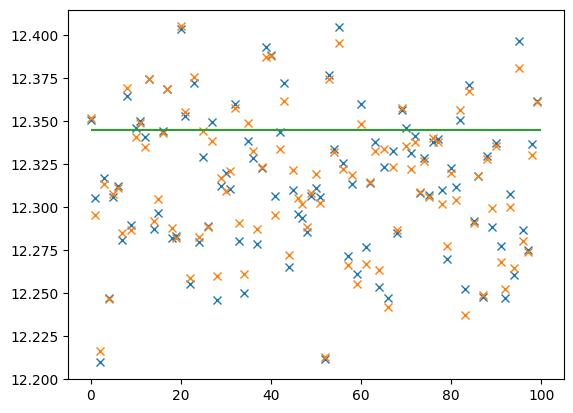

In [39]:
all_estimates = np.array(estimate_list)
plt.plot(all_estimates[:, 0], 'x')
plt.plot(all_estimates[:, 1], 'x')
plt.hlines(true_mean, 0, 100, color="C2")

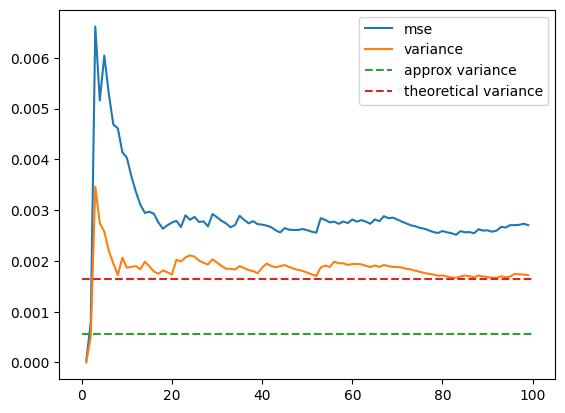

In [41]:
mse_estimates = [np.mean((all_estimates[:i, 0] - true_mean)**2) for i in range(1, len(all_estimates))]
var_estimates = [np.var(all_estimates[:i, 0]) for i in range(1, len(all_estimates))]

estimator = Estimator(sample_allocation, pilot_covariance_matrix)
approx_variance = estimator.approximate_variance
theoretical_variance = estimator.get_theoretical_variance(true_covariance)

plt.plot(np.arange(1, 100), mse_estimates, label="mse")
plt.plot(np.arange(1, 100), var_estimates, label="variance")
plt.plot([0, 100], [approx_variance]*2, '--', label="approx variance")
plt.plot([0, 100], [theoretical_variance]*2, '--', label="theoretical variance")
plt.legend()


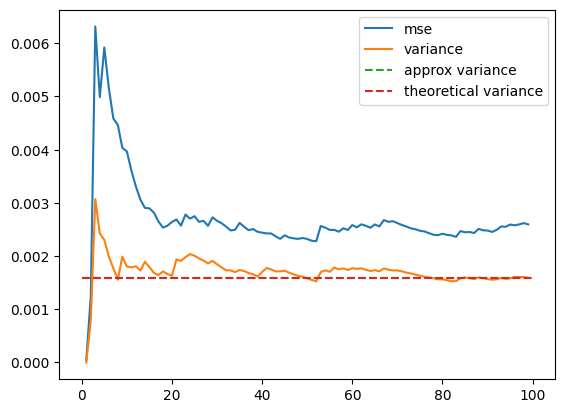

In [42]:
mse_estimates = [np.mean((all_estimates[:i, 1] - true_mean)**2) for i in range(1, len(all_estimates))]
var_estimates = [np.var(all_estimates[:i, 1]) for i in range(1, len(all_estimates))]

estimator = Estimator(sample_allocation, true_covariance)
approx_variance = estimator.approximate_variance
theoretical_variance = estimator.get_theoretical_variance(true_covariance)

plt.plot(np.arange(1, 100), mse_estimates, label="mse")
plt.plot(np.arange(1, 100), var_estimates, label="variance")
plt.plot([0, 100], [approx_variance]*2, '--', label="approx variance")
plt.plot([0, 100], [theoretical_variance]*2, '--', label="theoretical variance")
plt.legend()

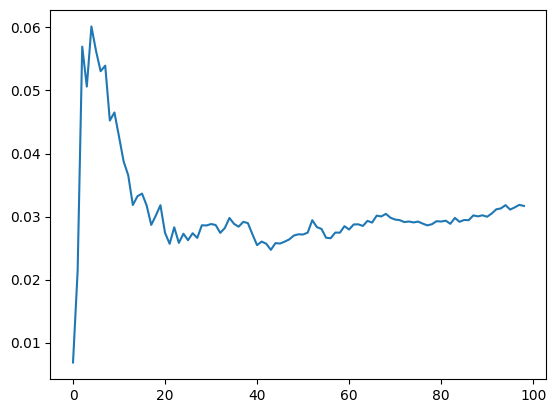

In [44]:
plt.plot(np.sqrt(np.array(mse_estimates)-np.array(var_estimates)))